# Đánh giá ban đầu — Logistic Regression và LightGBM

Ta đối chiếu dự báo trên cùng validation theo thời gian, chất lượng xác suất và độ nhạy với hai ngày bất thường. Các mô hình dùng đúng 18 biến đã chuẩn bị; notebook không đọc test. Validation đang được dùng để tìm hiểu và lựa chọn cách làm nên không phải đánh giá độc lập cuối cùng.

## 1. Nạp dữ liệu và xác minh dự báo

Kiểm tra khóa và nhãn giữa các file để hai mô hình được so sánh trên cùng quan sát. Hai mô hình đã lưu chỉ được nạp từ artifact nội bộ của project.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from IPython.display import display

ROOT=Path.cwd()
if ROOT.name == 'research' and ROOT.parent.name == 'notebooks': ROOT = ROOT.parent
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
if (ROOT/'.deps').is_dir(): sys.path.insert(0,str(ROOT/'.deps'))
from propensity_v2.prepared_data import load_prepared_split
DATA=ROOT/'artifacts'/'data_preparation'
OUT=ROOT/'artifacts'/'research'/'model_evaluation_validation'
train,features=load_prepared_split(DATA,'train')
val,features_val=load_prepared_split(DATA,'validation')
assert features==features_val and train.snapshot_day.max()+7 < val.snapshot_day.min()
saved=pd.read_parquet(ROOT/'artifacts'/'research'/'modeling_lightgbm'/'validation_predictions.parquet')
frame=val.merge(saved,on=['household_key','snapshot_day'],validate='one_to_one',how='left',suffixes=('','_saved'))
assert len(frame)==len(val) and frame.target_any_basket.eq(frame.target_any_basket_saved).all()
assert frame[['probability','logistic_probability','lightgbm_probability']].notna().all().all()
models={}
for name,path in [('Logistic Regression',ROOT/'artifacts'/'research'/'modeling_logistic'/'logistic_regression.joblib'),('LightGBM',ROOT/'artifacts'/'research'/'modeling_lightgbm'/'lightgbm.joblib')]:
    bundle=joblib.load(path); assert bundle['features']==features and bundle['target']=='target_any_basket'
    models[name]=bundle['model']
for name,col in [('Logistic Regression','logistic_probability'),('LightGBM','lightgbm_probability')]:
    assert np.allclose(models[name].predict_proba(frame[features])[:,1],frame[col])
print('Train:',len(train),'| Validation:',len(frame),'| Số biến:',len(features))

Train: 129834 | Validation: 27480 | Số biến: 18


## 2. Kết quả từng cutoff

Mỗi tuần đánh giá Brier, log loss, ROC-AUC và lift top 10%. Trường hợp đồng điểm tại ngưỡng, lift dùng kỳ vọng chọn ngẫu nhiên trong nhóm đồng điểm. Chênh lệch LightGBM trừ Logistic được tính trên cùng cutoff, không coi 11 tuần là mẫu độc lập để khẳng định ý nghĩa thống kê.

In [2]:
def top_lift(y,p):
    y=np.asarray(y); p=np.asarray(p); k=int(np.ceil(.1*len(y)))
    t=np.partition(p,len(p)-k)[len(p)-k]; higher=p>t; ties=p==t
    precision=(y[higher].sum()+(k-higher.sum())*y[ties].mean())/k
    return float(precision/y.mean()) if y.mean() else np.nan
def score(y,p):
    y=np.asarray(y);p=np.asarray(p)
    return {'brier':brier_score_loss(y,p),'log_loss':log_loss(y,p,labels=[0,1]),
            'roc_auc':roc_auc_score(y,p) if np.unique(y).size==2 else np.nan,
            'lift_10':top_lift(y,p)}
columns={'Baseline':'probability','Logistic Regression':'logistic_probability','LightGBM':'lightgbm_probability'}
weekly=[]
for cutoff,g in frame.groupby('snapshot_day',sort=True):
    for name,col in columns.items(): weekly.append({'snapshot_day':cutoff,'model':name,'rows':len(g),**score(g.target_any_basket,g[col])})
weekly=pd.DataFrame(weekly)
display(weekly.pivot(index='snapshot_day',columns='model',values='lift_10'))
pairs=[]
for metric in ['brier','log_loss','roc_auc','lift_10']:
    wide=weekly.pivot(index='snapshot_day',columns='model',values=metric)
    delta=wide['LightGBM']-wide['Logistic Regression']
    pairs.append({'metric':metric,'mean_delta':delta.mean(),'min_delta':delta.min(),'max_delta':delta.max(),
                  'cutoffs_lightgbm_better':int((delta<0).sum() if metric in ('brier','log_loss') else (delta>0).sum()),
                  'cutoffs':len(delta)})
weekly_delta=pd.DataFrame(pairs); display(weekly_delta)

model,Baseline,LightGBM,Logistic Regression
snapshot_day,,,
551,1.329648,1.847577,1.824954
558,1.324586,1.756754,1.756754
565,1.310870,1.770641,1.763294
572,1.306429,1.772894,1.780312
579,1.320858,1.846936,1.839208
586,1.311952,1.729660,1.736807
593,1.298422,1.773375,1.758473
600,1.281908,1.762427,1.769801
607,1.308284,1.749147,1.727282


,metric,mean_delta,min_delta,max_delta,cutoffs_lightgbm_better,cutoffs
0,brier,-0.001983,-0.003389,-0.000346,11,11
1,log_loss,-0.006266,-0.009375,-0.002296,11,11
2,roc_auc,0.003598,-0.000204,0.006209,10,11
3,lift_10,0.008838,-0.007418,0.022623,7,11


## 3. Reliability và xác suất

Nhóm theo khoảng xác suất cố định 0,1; biểu đồ so sánh xác suất trung bình với tỷ lệ mua quan sát. Brier và log loss phản ánh cả calibration lẫn khả năng phân biệt; biểu đồ là kiểm tra mô tả và nhạy với quy mô bin. Không fit bộ hiệu chỉnh trên validation rồi báo kết quả trên chính validation. Nếu hiệu chỉnh sau này, cần phân tách theo thời gian và đánh giá riêng.

,bin,n,mean_prediction,observed,model
0,"(-0.001, 0.1]",1992,0.065620,0.070281,Baseline
1,"(0.1, 0.2]",879,0.135447,0.135381,Baseline
2,"(0.2, 0.3]",1934,0.208393,0.221820,Baseline
3,"(0.3, 0.4]",3231,0.351802,0.357474,Baseline
4,"(0.4, 0.5]",3606,0.490408,0.489462,Baseline
5,"(0.7, 0.8]",15838,0.704739,0.708044,Baseline
6,"(-0.001, 0.1]",1621,0.046915,0.059840,Logistic Regression
7,"(0.1, 0.2]",1998,0.156446,0.144645,Logistic Regression
8,"(0.2, 0.3]",3223,0.254815,0.234564,Logistic Regression
9,"(0.3, 0.4]",3469,0.348559,0.347939,Logistic Regression


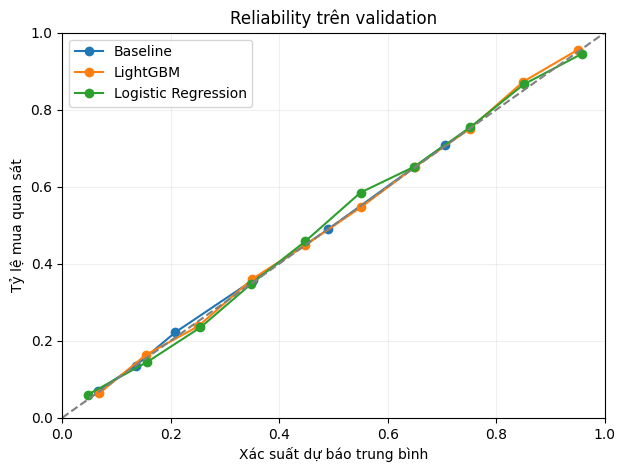

In [3]:
calibration=[]
for name,col in columns.items():
    t=frame.assign(bin=pd.cut(frame[col],np.linspace(0,1,11),include_lowest=True))
    table=t.groupby('bin',observed=True).agg(n=('target_any_basket','size'),mean_prediction=(col,'mean'),observed=('target_any_basket','mean')).reset_index()
    table['model']=name;calibration.append(table)
calibration=pd.concat(calibration,ignore_index=True)
display(calibration)
fig,ax=plt.subplots(figsize=(7,5))
for name,g in calibration.groupby('model'):
    ax.plot(g.mean_prediction,g.observed,marker='o',label=name)
ax.plot([0,1],[0,1],linestyle='--',color='gray');ax.set(xlim=(0,1),ylim=(0,1),xlabel='Xác suất dự báo trung bình',ylabel='Tỷ lệ mua quan sát',title='Reliability trên validation');ax.grid(alpha=.2);ax.legend();plt.show()

## 4. Độ nhạy với ngày 278 và 643

Hai phép kiểm tra trả lời hai câu hỏi khác nhau:

1. **Tập đánh giá:** đếm các cửa sổ validation chạm ngày bất thường trước khi thử loại. Nếu không có cửa sổ nào, phép loại này không thay đổi tập đánh giá; không được diễn giải thành bằng chứng dữ liệu không bị ảnh hưởng.
2. **Huấn luyện lại:** giữ nguyên validation và cấu hình, so sánh mô hình gốc với mô hình loại khỏi train các cửa sổ nhãn chạm ngày bất thường; một kịch bản riêng loại thêm cửa sổ lịch sử 90 ngày. Cờ không chứng minh thiếu dữ liệu. Cửa sổ 180 ngày và thời gian quan sát dài hơn vẫn có thể chứa ảnh hưởng; đây không phải xử lý triệt để.

In [4]:
flag_cols=['label_window_touches_anomaly','history_90d_touches_anomaly','history_180d_touches_anomaly']
flag_counts=pd.DataFrame({'train':train[flag_cols].sum(),'validation':frame[flag_cols].sum()})
display(flag_counts)
scenario_masks={
    'Đầy đủ':np.ones(len(train),dtype=bool),
    'Loại cửa sổ nhãn':~train.label_window_touches_anomaly.to_numpy(),
    'Loại nhãn và lịch sử 90d':~(train.label_window_touches_anomaly | train.history_90d_touches_anomaly).to_numpy(),
}
sensitivity=[]
for model_name, original in models.items():
    for scenario, mask in scenario_masks.items():
        if scenario=='Đầy đủ': candidate=original
        else:
            candidate=clone(original)
            candidate.fit(train.loc[mask,features],train.loc[mask,'target_any_basket'])
        p=candidate.predict_proba(frame[features])[:,1]
        weekly_lift=np.mean([top_lift(frame.loc[ix,'target_any_basket'],p[ix]) for ix in frame.groupby('snapshot_day').indices.values()])
        metrics=score(frame.target_any_basket,p)
        sensitivity.append({'model':model_name,'scenario':scenario,'train_rows':int(mask.sum()),
                            'brier':metrics['brier'],'log_loss':metrics['log_loss'],'roc_auc':metrics['roc_auc'],
                            'weekly_lift_mean':weekly_lift})
sensitivity=pd.DataFrame(sensitivity);display(sensitivity)

,train,validation
label_window_touches_anomaly,2496,0
history_90d_touches_anomaly,32461,0
history_180d_touches_anomaly,64925,0


,model,scenario,train_rows,brier,log_loss,roc_auc,weekly_lift_mean
0,Logistic Regression,Đầy đủ,129834,0.166371,0.501671,0.833017,1.777743
1,Logistic Regression,Loại cửa sổ nhãn,127338,0.166371,0.501684,0.833021,1.777066
2,Logistic Regression,Loại nhãn và lịch sử 90d,94877,0.166406,0.501664,0.832989,1.777679
3,LightGBM,Đầy đủ,129834,0.164389,0.495405,0.836662,1.786582
4,LightGBM,Loại cửa sổ nhãn,127338,0.164404,0.495456,0.836678,1.785938
5,LightGBM,Loại nhãn và lịch sử 90d,94877,0.164554,0.495881,0.836530,1.788575


## 5. Kiểm tra nhóm feature

Hoán vị đồng thời các feature trong một nhóm trên validation và đo mức tăng Brier so với dự báo gốc. Một lần hoán vị với seed cố định chỉ là kiểm tra thăm dò, không phải tầm quan trọng ổn định hay tác động nhân quả. Các nhóm tương quan có thể thay thế nhau; hoán vị có thể tạo tổ hợp không tự nhiên. Vì kiểm tra dùng validation, việc ra quyết định từ kết quả này làm tăng mức độ sử dụng validation.

In [5]:
groups={'Recency':['recency_days'],'Thời gian quan sát':['observed_tenure_days']}
for metric in ['baskets','sales','line_items','active_days']:
    groups[metric]=[f'{metric}_{w}d' for w in (7,30,90,180)]
assert sorted(sum(groups.values(),[]))==sorted(features)
rng=np.random.default_rng(42); permutation=rng.permutation(len(frame))
importance=[]
for name,model in models.items():
    base=model.predict_proba(frame[features])[:,1]
    base_brier=brier_score_loss(frame.target_any_basket,base)
    for group,cols in groups.items():
        x=frame[features].copy(); x.loc[:,cols]=x.loc[:,cols].to_numpy()[permutation]
        shuffled=model.predict_proba(x)[:,1]
        importance.append({'model':name,'feature_group':group,'brier_increase':brier_score_loss(frame.target_any_basket,shuffled)-base_brier})
importance=pd.DataFrame(importance);display(importance.pivot(index='feature_group',columns='model',values='brier_increase'))

model,LightGBM,Logistic Regression
feature_group,,
Recency,0.007534,1.077228e-02
Thời gian quan sát,-0.000009,8.224823e-07
active_days,0.088940,1.666036e-01
baskets,0.001176,1.385408e-02
line_items,0.003011,6.096278e-03
sales,0.000854,3.147243e-04


**Kết quả thăm dò:** LightGBM có Brier và log loss thấp hơn Logistic Regression ở cả 11 cutoff, ROC-AUC cao hơn ở 10/11 cutoff và lift cao hơn ở 7/11 cutoff. Chênh lệch nhỏ và các cutoff phụ thuộc nhau; chưa kết luận ý nghĩa thống kê. Không có cửa sổ validation được gắn cờ trong ba loại cửa sổ đang xét. Khi huấn luyện lại sau khi loại cửa sổ nhãn, hoặc loại thêm lịch sử 90 ngày trong train, các chỉ số validation thay đổi ít trong những kịch bản này; cửa sổ 180 ngày và lịch sử tích lũy vẫn có thể mang ảnh hưởng.


## 6. Bàn giao và giới hạn

Kết quả chỉ áp dụng cho validation và các kịch bản đã kiểm tra. So sánh nhóm khách có lịch sử ngắn không đáng tin cậy vì validation chỉ có 2 household dưới 180 ngày. Không sử dụng test để quyết định feature, hyperparameter hoặc calibration. Kiểm chứng cuối vẫn cần dữ liệu tương lai chưa dùng trong phát triển.

In [6]:
OUT.mkdir(parents=True,exist_ok=True)
weekly.to_csv(OUT/'weekly_metrics.csv',index=False,encoding='utf-8-sig')
weekly_delta.to_csv(OUT/'weekly_differences.csv',index=False,encoding='utf-8-sig')
calibration.astype({'bin':'str'}).to_csv(OUT/'calibration_bins.csv',index=False,encoding='utf-8-sig')
flag_counts.to_csv(OUT/'anomaly_window_counts.csv',encoding='utf-8-sig')
sensitivity.to_csv(OUT/'anomaly_training_sensitivity.csv',index=False,encoding='utf-8-sig')
importance.to_csv(OUT/'group_permutation_brier.csv',index=False,encoding='utf-8-sig')
print('Đã lưu kết quả:',OUT)

Đã lưu kết quả: artifacts\model_evaluation_validation
